In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
print("Pandas version:", pd.__version__)
print("Requests version:", requests.__version__)

Pandas version: 3.1.0
Requests version: 2.32.3


In [ ]:
API_FOOTBALL_KEY = "API"

url = "https://v3.football.api-sports.io/leagues"

headers = {
    "x-apisports-key": API_FOOTBALL_KEY
}

response = requests.get(
    url,
    headers=headers,
    params={"country": "Germany"},
    timeout=30
)

print("Status code:", response.status_code)

if response.status_code == 200:
    data = response.json()
    print("API response:", data.get("results"))
    display(pd.json_normalize(data["response"]).head())
else:
    print(response.text)

Status code: 200
API response: 34


,seasons,league.id,league.name,league.type,league.logo,country.name,country.code,country.flag
0,"[{'year': 2010, 'start': '2010-08-20', 'end': ...",78,Bundesliga,League,https://media.api-sports.io/football/leagues/7...,Germany,DE,https://media.api-sports.io/flags/de.svg
1,"[{'year': 2011, 'start': '2011-07-15', 'end': ...",79,2. Bundesliga,League,https://media.api-sports.io/football/leagues/7...,Germany,DE,https://media.api-sports.io/flags/de.svg
2,"[{'year': 2011, 'start': '2011-07-22', 'end': ...",80,3. Liga,League,https://media.api-sports.io/football/leagues/8...,Germany,DE,https://media.api-sports.io/flags/de.svg
3,"[{'year': 2011, 'start': '2011-07-23', 'end': ...",529,Super Cup,Cup,https://media.api-sports.io/football/leagues/5...,Germany,DE,https://media.api-sports.io/flags/de.svg
4,"[{'year': 2011, 'start': '2011-07-29', 'end': ...",81,DFB Pokal,Cup,https://media.api-sports.io/football/leagues/8...,Germany,DE,https://media.api-sports.io/flags/de.svg


In [4]:
url = "https://v3.football.api-sports.io/standings"

params = {
    "league": 78,
    "season": 2024
}

response = requests.get(
    url,
    headers=headers,
    params=params,
    timeout=30
)

print("Status code:", response.status_code)

if response.status_code == 200:
    data = response.json()

    print("Results:", data.get("results"))

    if data.get("response"):
        standings = data["response"][0]["league"]["standings"][0]
        df_standings = pd.json_normalize(standings)

        display(df_standings.head())
    else:
        print("No standings data found.")
else:
    print(response.text)

Status code: 200
Results: 1


,rank,points,goalsDiff,group,form,status,description,update,team.id,team.name,...,home.draw,home.lose,home.goals.for,home.goals.against,away.played,away.win,away.draw,away.lose,away.goals.for,away.goals.against
0,1,82,67,Bundesliga,WWDWW,same,Promotion - Champions League (League phase: ),2025-05-28T00:00:00+00:00,157,Bayern München,...,2,1,53,16,17,11,5,1,46,16
1,2,69,29,Bundesliga,DLDWD,same,Promotion - Champions League (League phase: ),2025-05-28T00:00:00+00:00,168,Bayer Leverkusen,...,4,3,36,22,17,9,8,0,36,21
2,3,60,22,Bundesliga,WDDWD,same,Promotion - Champions League (League phase: ),2025-05-28T00:00:00+00:00,169,Eintracht Frankfurt,...,4,3,41,22,17,7,5,5,27,24
3,4,57,20,Bundesliga,WWWWW,same,Promotion - Champions League (League phase: ),2025-05-28T00:00:00+00:00,165,Borussia Dortmund,...,3,3,44,19,17,6,3,8,27,32
4,5,55,-4,Bundesliga,LWDWW,same,Promotion - Europa League (League phase: ),2025-05-28T00:00:00+00:00,160,SC Freiburg,...,3,5,32,26,17,7,4,6,17,27


In [5]:
#Important columns
columns = [
    "rank",
    "team.name",
    "points",
    "goalsDiff",
    "all.played",
    "all.win",
    "all.draw",
    "all.lose",
    "all.goals.for",
    "all.goals.against"
]

df = df_standings[columns].copy()

#Rename columns
df.columns = [
    "position",
    "club",
    "points",
    "goal_difference",
    "matches_played",
    "wins",
    "draws",
    "losses",
    "goals_scored",
    "goals_conceded"
]

display(df.head())
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

,position,club,points,goal_difference,matches_played,wins,draws,losses,goals_scored,goals_conceded
0,1,Bayern München,82,67,34,25,7,2,99,32
1,2,Bayer Leverkusen,69,29,34,19,12,3,72,43
2,3,Eintracht Frankfurt,60,22,34,17,9,8,68,46
3,4,Borussia Dortmund,57,20,34,17,6,11,71,51
4,5,SC Freiburg,55,-4,34,16,7,11,49,53


Dataset shape: (18, 10)

Missing values:
position           0
club               0
points             0
goal_difference    0
matches_played     0
wins               0
draws              0
losses             0
goals_scored       0
goals_conceded     0
dtype: int64


In [6]:
#Check data types
print("Data types:")
print(df.dtypes)

#Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

#Check duplicate club names
print("Duplicate clubs:", df["club"].duplicated().sum())

#Convert statistics to numeric types
numeric_columns = [
    "position", "points", "goal_difference",
    "matches_played", "wins", "draws", "losses",
    "goals_scored", "goals_conceded"
]

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)

#Remove duplicates and reset index
df = df.drop_duplicates(subset="club")
df = df.reset_index(drop=True)

print("\nFinal dataset shape:", df.shape)
display(df.head())

Data types:
position           int64
club                 str
points             int64
goal_difference    int64
matches_played     int64
wins               int64
draws              int64
losses             int64
goals_scored       int64
goals_conceded     int64
dtype: object

Duplicate rows: 0
Duplicate clubs: 0

Final dataset shape: (18, 10)


,position,club,points,goal_difference,matches_played,wins,draws,losses,goals_scored,goals_conceded
0,1,Bayern München,82,67,34,25,7,2,99,32
1,2,Bayer Leverkusen,69,29,34,19,12,3,72,43
2,3,Eintracht Frankfurt,60,22,34,17,9,8,68,46
3,4,Borussia Dortmund,57,20,34,17,6,11,71,51
4,5,SC Freiburg,55,-4,34,16,7,11,49,53


In [7]:
#Descriptive statistics
display(df.describe().round(2))

,position,points,goal_difference,matches_played,wins,draws,losses,goals_scored,goals_conceded
count,18.00,18.00,18.00,18.0,18.00,18.00,18.00,18.00,18.00
mean,9.50,46.72,0.00,34.0,12.72,8.56,12.72,53.28,53.28
std,5.34,15.21,24.91,0.0,4.99,2.09,5.50,17.45,11.31
min,1.00,25.00,-34.00,34.0,6.00,5.00,2.00,28.00,32.00
25%,5.25,34.00,-16.00,34.0,8.50,7.00,10.25,39.25,46.50
50%,9.50,47.50,-2.50,34.0,13.00,8.50,12.50,53.50,52.00
75%,13.75,54.25,11.75,34.0,15.50,10.00,15.75,62.00,57.00
max,18.00,82.00,67.00,34.0,25.00,12.00,21.00,99.00,80.00


In [8]:
#Top 5 clubs by points
print("Top 5 clubs by points:")
display(df.nlargest(5, "points")[["position", "club", "points"]])

#Bottom 5 clubs by points
print("Bottom 5 clubs by points:")
display(df.nsmallest(5, "points")[["position", "club", "points"]])

#Top 5 clubs by goals scored
print("Top 5 clubs by goals scored:")
display(df.nlargest(5, "goals_scored")[["club", "goals_scored"]])

Top 5 clubs by points:


,position,club,points
0,1,Bayern München,82
1,2,Bayer Leverkusen,69
2,3,Eintracht Frankfurt,60
3,4,Borussia Dortmund,57
4,5,SC Freiburg,55


Bottom 5 clubs by points:


,position,club,points
16,17,Holstein Kiel,25
17,18,VfL Bochum,25
15,16,1. FC Heidenheim,29
13,14,FC St. Pauli,32
14,15,1899 Hoffenheim,32


Top 5 clubs by goals scored:


,club,goals_scored
0,Bayern München,99
1,Bayer Leverkusen,72
3,Borussia Dortmund,71
2,Eintracht Frankfurt,68
8,VfB Stuttgart,64


In [9]:
#Correlation matrix
correlation_columns = [
    "points", "wins", "draws", "losses",
    "goals_scored", "goals_conceded", "goal_difference"
]

correlation = df[correlation_columns].corr()

display(correlation.round(2))

,points,wins,draws,losses,goals_scored,goals_conceded,goal_difference
points,1.00,0.99,0.18,-0.97,0.86,-0.77,0.95
wins,0.99,1.00,0.04,-0.92,0.88,-0.75,0.95
draws,0.18,0.04,1.00,-0.42,-0.01,-0.26,0.11
losses,-0.97,-0.92,-0.42,1.00,-0.80,0.78,-0.91
goals_scored,0.86,0.88,-0.01,-0.80,1.00,-0.48,0.92
goals_conceded,-0.77,-0.75,-0.26,0.78,-0.48,1.00,-0.79
goal_difference,0.95,0.95,0.11,-0.91,0.92,-0.79,1.00


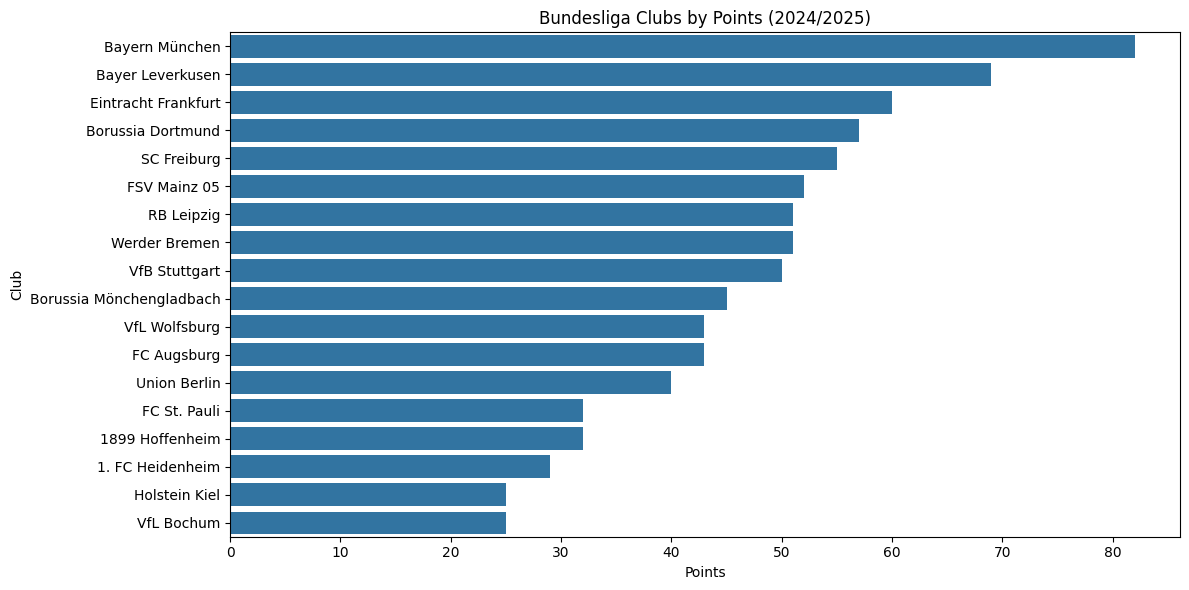

In [10]:
plt.figure(figsize=(12, 6))

df_sorted = df.sort_values("points", ascending=False)

sns.barplot(data=df_sorted, x="points", y="club")

plt.title("Bundesliga Clubs by Points (2024/2025)")
plt.xlabel("Points")
plt.ylabel("Club")
plt.tight_layout()
plt.show()

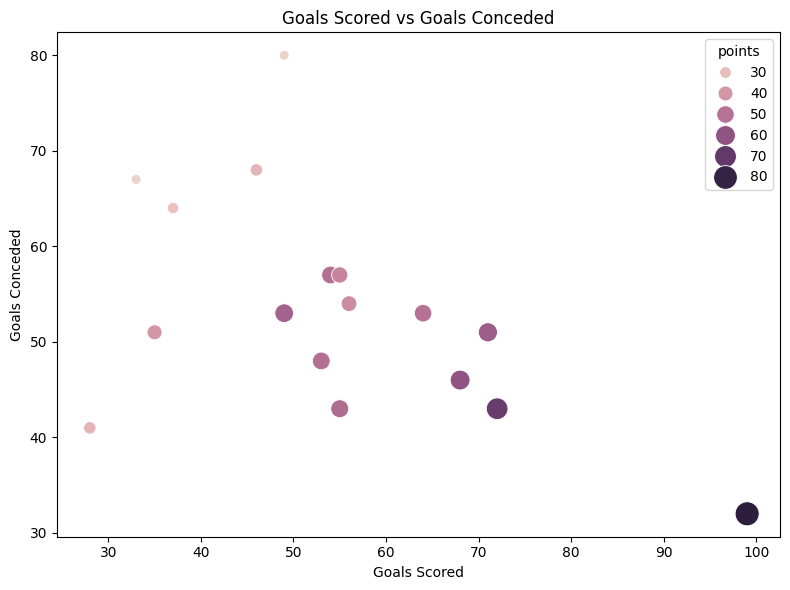

In [11]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="goals_scored",
    y="goals_conceded",
    size="points",
    hue="points",
    sizes=(50, 300)
)

plt.title("Goals Scored vs Goals Conceded")
plt.xlabel("Goals Scored")
plt.ylabel("Goals Conceded")
plt.tight_layout()
plt.show()

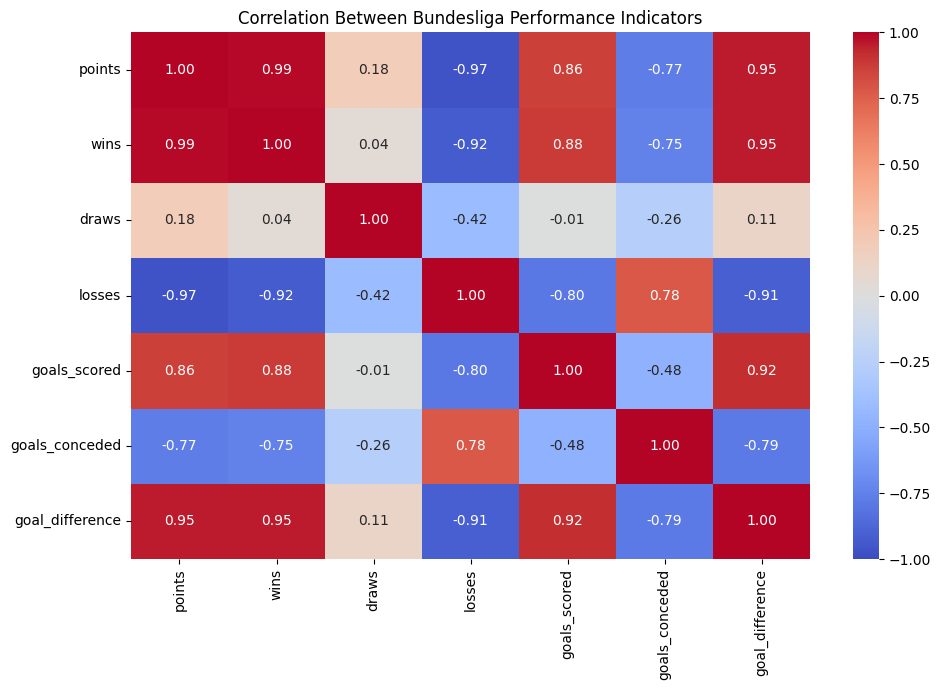

In [12]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Bundesliga Performance Indicators")
plt.tight_layout()
plt.show()

In [13]:
#Best and lowest performing clubs
best_club = df.loc[df["points"].idxmax()]
lowest_club = df.loc[df["points"].idxmin()]

#Highest and lowest scoring clubs
top_scoring = df.loc[df["goals_scored"].idxmax()]
lowest_scoring = df.loc[df["goals_scored"].idxmin()]

#Best and worst goal difference
best_goal_difference = df.loc[df["goal_difference"].idxmax()]
worst_goal_difference = df.loc[df["goal_difference"].idxmin()]

print("EDA Summary: Bundesliga 2024/2025")

print(
    f"Highest points: {best_club['club']} "
    f"({best_club['points']} points)"
)

print(
    f"Lowest points: {lowest_club['club']} "
    f"({lowest_club['points']} points)"
)

print(
    f"Most goals scored: {top_scoring['club']} "
    f"({top_scoring['goals_scored']} goals)"
)

print(
    f"Fewest goals scored: {lowest_scoring['club']} "
    f"({lowest_scoring['goals_scored']} goals)"
)

print(
    f"Best goal difference: {best_goal_difference['club']} "
    f"({best_goal_difference['goal_difference']})"
)

print(
    f"Worst goal difference: {worst_goal_difference['club']} "
    f"({worst_goal_difference['goal_difference']})"
)

print(
    f"Average points: {df['points'].mean():.2f}"
)

print(
    f"Average goals scored: {df['goals_scored'].mean():.2f}"
)

EDA Summary: Bundesliga 2024/2025
Highest points: Bayern München (82 points)
Lowest points: Holstein Kiel (25 points)
Most goals scored: Bayern München (99 goals)
Fewest goals scored: FC St. Pauli (28 goals)
Best goal difference: Bayern München (67)
Worst goal difference: VfL Bochum (-34)
Average points: 46.72
Average goals scored: 53.28


In [14]:
df.to_csv("bundesliga_2024_2025.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [15]:
#Wikipedia page
wiki_url = "https://en.wikipedia.org/wiki/2024%E2%80%9325_Bundesliga"

wiki_response = requests.get(
    wiki_url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=30
)

print("Status code:", wiki_response.status_code)

#BeautifulSoup
soup = BeautifulSoup(wiki_response.text, "html.parser")

#ables on the page
tables = soup.find_all("table", class_="wikitable")

print("Number of tables found:", len(tables))

#able headers
for i, table in enumerate(tables):
    headers = [
        th.get_text(" ", strip=True)
        for th in table.find_all("th")
    ]
    print(f"Table {i}: {headers[:12]}")

Status code: 200
Number of tables found: 14
Table 0: ['Promoted from 2023–24 2. Bundesliga', 'Relegated from 2023–24 Bundesliga']
Table 1: ['Team', 'Location', 'Stadium', 'Capacity', 'R.']
Table 2: ['Team', 'Manager', 'Captain', 'Kit manufacturer', 'Shirt sponsor', 'Front', 'Sleeve']
Table 3: ['Team', 'Outgoing', 'Manner', 'Exit date', 'Position in table', 'Incoming', 'Incoming date', 'Ref.', 'Announced on', 'Departed on', 'Announced on', 'Arrived on']
Table 4: ['Pos', 'Team v t e', 'Pld', 'W', 'D', 'L', 'GF', 'GA', 'GD', 'Pts', 'Qualification or relegation', 'Bayern Munich (C)']
Table 5: ['Home \\ Away', 'AUG', 'UNB', 'BOC', 'BRE', 'DOR', 'FRA', 'FRE', 'HEI', 'HOF', 'KIE', 'LEI']
Table 6: ['Team 1', 'Agg. Tooltip Aggregate score', 'Team 2', '1st leg', '2nd leg']
Table 7: ['Rank', 'Player', 'Club', 'Goals [ 55 ]']
Table 8: ['Player', 'Club', 'Against', 'Result', 'Date']
Table 9: ['Rank', 'Player', 'Club', 'Clean sheets [ 56 ]']
Table 10: ['Month', 'Player of the Month', 'Rookie of the 

In [18]:
#op scorers table
scorers_table = tables[7]

#HTML table to a pandas DataFrame
from io import StringIO

df_scorers = pd.read_html(
    StringIO(str(scorers_table))
)[0]

display(df_scorers.head(10))

print("\nColumn names:")
print(df_scorers.columns.tolist())

,Rank,Player,Club,Goals[55]
0,1,Harry Kane,Bayern Munich,26
1,2,Serhou Guirassy,Borussia Dortmund,21
2,2,Patrik Schick,Bayer Leverkusen,21
3,4,Jonathan Burkardt,Mainz 05,18
4,5,Tim Kleindienst,Borussia Mönchengladbach,16
5,6,Ermedin Demirović,VfB Stuttgart,15
6,6,Hugo Ekitike,Eintracht Frankfurt,15
7,6,Omar Marmoush[a],Eintracht Frankfurt,15
8,9,Benjamin Šeško,RB Leipzig,13
9,10,Jamal Musiala,Bayern Munich,12



Column names:
['Rank', 'Player', 'Club', 'Goals[55]']


In [19]:
#Rename columns
df_scorers.columns = ["rank", "player", "club", "goals"]

df_scorers["player"] = (
    df_scorers["player"]
    .str.replace(r"\[.*?\]", "", regex=True)
    .str.strip()
)

#Convert numeric columns
df_scorers["rank"] = pd.to_numeric(df_scorers["rank"], errors="coerce")
df_scorers["goals"] = pd.to_numeric(df_scorers["goals"], errors="coerce")

#Remove duplicates and missing values
df_scorers = df_scorers.dropna(subset=["player", "club", "goals"])
df_scorers = df_scorers.drop_duplicates(subset=["player", "club"])
df_scorers = df_scorers.reset_index(drop=True)

display(df_scorers)
print("Dataset shape:", df_scorers.shape)
print("Missing values:", df_scorers.isnull().sum().sum())

,rank,player,club,goals
0,1,Harry Kane,Bayern Munich,26
1,2,Serhou Guirassy,Borussia Dortmund,21
2,2,Patrik Schick,Bayer Leverkusen,21
3,4,Jonathan Burkardt,Mainz 05,18
4,5,Tim Kleindienst,Borussia Mönchengladbach,16
5,6,Ermedin Demirović,VfB Stuttgart,15
6,6,Hugo Ekitike,Eintracht Frankfurt,15
7,6,Omar Marmoush,Eintracht Frankfurt,15
8,9,Benjamin Šeško,RB Leipzig,13
9,10,Jamal Musiala,Bayern Munich,12


Dataset shape: (12, 4)
Missing values: 0


In [20]:
#Match Wikipedia club names with API club names
club_names = {
    "Bayern Munich": "Bayern München",
    "Mainz 05": "FSV Mainz 05",
    "Eintracht Frankfurt": "Eintracht Frankfurt",
    "Bayer Leverkusen": "Bayer Leverkusen",
    "Borussia Dortmund": "Borussia Dortmund",
    "Borussia Mönchengladbach": "Borussia Mönchengladbach",
    "VfB Stuttgart": "VfB Stuttgart",
    "RB Leipzig": "RB Leipzig"
}

df_scorers["club_api"] = df_scorers["club"].replace(club_names)

scorer_stats = (
    df_scorers.groupby("club_api")
    .agg(
        top_scorers_count=("player", "count"),
        top_scorers_goals=("goals", "sum")
    )
    .reset_index()
)

#Merge
df_merged = df.merge(
    scorer_stats,
    left_on="club",
    right_on="club_api",
    how="left"
)

df_merged["top_scorers_count"] = (
    df_merged["top_scorers_count"].fillna(0).astype(int)
)

df_merged["top_scorers_goals"] = (
    df_merged["top_scorers_goals"].fillna(0).astype(int)
)

df_merged = df_merged.drop(columns=["club_api"])
df_merged = df_merged.reset_index(drop=True)

display(
    df_merged[
        ["club", "points", "goals_scored",
         "top_scorers_count", "top_scorers_goals"]
    ].sort_values("top_scorers_goals", ascending=False)
)

,club,points,goals_scored,top_scorers_count,top_scorers_goals
0,Bayern München,82,99,3,50
2,Eintracht Frankfurt,60,68,2,30
8,VfB Stuttgart,50,64,2,27
1,Bayer Leverkusen,69,72,1,21
3,Borussia Dortmund,57,71,1,21
5,FSV Mainz 05,52,55,1,18
9,Borussia Mönchengladbach,45,55,1,16
6,RB Leipzig,51,53,1,13
4,SC Freiburg,55,49,0,0
7,Werder Bremen,51,54,0,0


In [21]:
#Merge results
matched_clubs = (df_merged["top_scorers_count"] > 0).sum()
unmatched_clubs = (df_merged["top_scorers_count"] == 0).sum()

print("Total clubs:", len(df_merged))
print("Clubs matched with top scorers:", matched_clubs)
print("Clubs without listed top scorers:", unmatched_clubs)

print("\nTop scorer data:")
display(
    df_merged[
        ["club", "top_scorers_count", "top_scorers_goals"]
    ].sort_values("top_scorers_goals", ascending=False)
)

Total clubs: 18
Clubs matched with top scorers: 8
Clubs without listed top scorers: 10

Top scorer data:


,club,top_scorers_count,top_scorers_goals
0,Bayern München,3,50
2,Eintracht Frankfurt,2,30
8,VfB Stuttgart,2,27
1,Bayer Leverkusen,1,21
3,Borussia Dortmund,1,21
5,FSV Mainz 05,1,18
9,Borussia Mönchengladbach,1,16
6,RB Leipzig,1,13
4,SC Freiburg,0,0
7,Werder Bremen,0,0


In [22]:
df_merged.to_csv("bundesliga_merged_2024_2025.csv", index=False)

print("Merged dataset saved successfully!")

Merged dataset saved successfully!


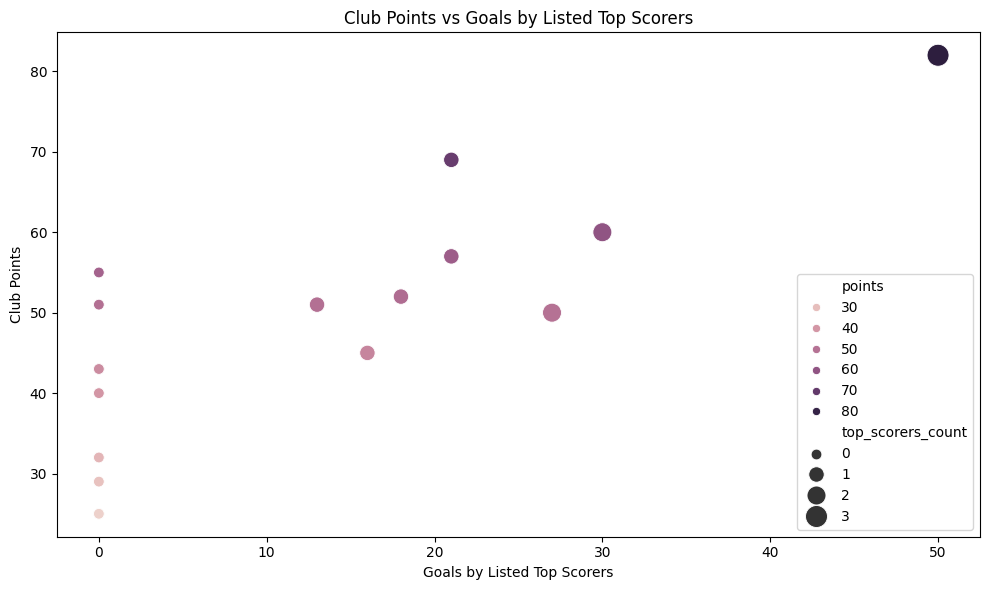

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_merged,
    x="top_scorers_goals",
    y="points",
    hue="points",
    size="top_scorers_count",
    sizes=(60, 250)
)

plt.title("Club Points vs Goals by Listed Top Scorers")
plt.xlabel("Goals by Listed Top Scorers")
plt.ylabel("Club Points")
plt.tight_layout()
plt.show()

In [24]:
print(
    "Correlation between points and top scorers' goals:",
    round(df_merged["points"].corr(df_merged["top_scorers_goals"]), 2)
)

print(
    "Correlation between points and total goals scored:",
    round(df_merged["points"].corr(df_merged["goals_scored"]), 2)
)

Correlation between points and top scorers' goals: 0.81
Correlation between points and total goals scored: 0.86


In [25]:
#merged dataset
df_merged.to_csv("bundesliga_merged_2024_2025.csv", index=False)

#cleaned top scorers dataset
df_scorers.to_csv("bundesliga_top_scorers_2024_2025.csv", index=False)

print("Both datasets saved successfully!")

Both datasets saved successfully!


In [26]:
best_club = df_merged.loc[df_merged["points"].idxmax()]
lowest_club = df_merged.loc[df_merged["points"].idxmin()]
top_scoring_club = df_merged.loc[df_merged["goals_scored"].idxmax()]
best_goal_difference = df_merged.loc[df_merged["goal_difference"].idxmax()]

matched_clubs = (df_merged["top_scorers_count"] > 0).sum()

print("CONCLUSIONS: Bundesliga 2024/2025")

print(
    f"1. {best_club['club']} finished first with "
    f"{best_club['points']} points."
)

print(
    f"2. {lowest_club['club']} had the lowest points total "
    f"({lowest_club['points']})."
)

print(
    f"3. {top_scoring_club['club']} scored the most team goals: "
    f"{top_scoring_club['goals_scored']}."
)

print(
    f"4. {best_goal_difference['club']} had the best goal difference: "
    f"{best_goal_difference['goal_difference']}."
)

print(
    f"5. {matched_clubs} out of {len(df_merged)} clubs "
    "had at least one player in the extracted top-scorers table."
)

print(
    f"6. The average points per club were "
    f"{df_merged['points'].mean():.2f}."
)

print(
    f"7. The average number of goals scored per club was "
    f"{df_merged['goals_scored'].mean():.2f}."
)

CONCLUSIONS: Bundesliga 2024/2025
1. Bayern München finished first with 82 points.
2. Holstein Kiel had the lowest points total (25).
3. Bayern München scored the most team goals: 99.
4. Bayern München had the best goal difference: 67.
5. 8 out of 18 clubs had at least one player in the extracted top-scorers table.
6. The average points per club were 46.72.
7. The average number of goals scored per club was 53.28.
